In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import os
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats


# Ajusta la carpeta si el Excel no está junto al notebook
archivo = Path("Datos/Clasificacion de Tickets 2021.xlsm")

df_original = pd.read_excel(archivo, sheet_name="Data")

# Trabajamos con una copia para conservar los datos originales
df = df_original.copy()
df.columns = df.columns.str.strip()

print("Forma del dataset:", df.shape)
print("Cantidad de registros:", df.shape[0])
print("Cantidad de variables:", df.shape[1])

display(df.head())
df.info()

print("\nFecha mínima de apertura:", df["Opened"].min())
print("Fecha máxima de apertura:", df["Opened"].max())

Forma del dataset: (11150, 42)
Cantidad de registros: 11150
Cantidad de variables: 42


,Number,State,Equipment Name,Assigned to,Updated,Opened,Repair Time,time 24,Description,Requested for,...,Day,im,Eq2 - Workgroup,Valid,Eq,Val,Duplicado,Tickets found,Total repair time,Time of response
0,REQ-1761298,Completed,Robusta,NaN,2026-08-24 22:40:13,2026-08-24 22:36:05,0.5,Completed,Me ayudas con el cierre de maquina robusta no ...,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
1,REQ-1761297,Completed,Robusta,NaN,2026-08-24 22:38:09,2026-08-24 22:34:44,0.5,Completed,Ma ayudan con alineación de cañón maquina robusta,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
2,REQ-1761296,Completed,Aguascalientes,NaN,2026-08-26 02:23:49,2026-08-24 22:33:22,0.5,Completed,Me avientan el sistema del valgate maquina agu...,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Aguascalientes,1.0,1.0,NaN,NaN,NaN
3,REQ-1761295,Completed,Robusta,NaN,2026-08-24 22:28:17,2026-08-24 22:27:06,1.0,Completed,me ayudan no abre la prensa,David Diaz,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
4,REQ-1761294,Completed,Robusta,NaN,2026-08-24 22:26:18,2026-08-24 22:25:02,1.0,Completed,favor de alinear unidad de inyeccion,David Diaz,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 11150 entries, 0 to 11149
Data columns (total 42 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   Number                            11150 non-null  str           
 1   State                             11147 non-null  str           
 2   Equipment Name                    11145 non-null  str           
 3   Assigned to                       0 non-null      float64       
 4   Updated                           8620 non-null   object        
 5   Opened                            11150 non-null  datetime64[us]
 6   Repair Time                       11147 non-null  float64       
 7   time 24                           11147 non-null  str           
 8   Description                       11149 non-null  object        
 9   Requested for                     11146 non-null  str           
 10  Functional area                   11145 non-null  str    

### Vamos a separar unicamente las variables mas relevantes para el porblema la columna Q, la columna AB y el nombre de la maquina.

### Eliminamos las filas con valores nulos en cualquiera de las filas

### Unimos en una nueva columna el nombre del equipo con la descripcion

In [56]:
import pandas as pd
import nltk
from nltk.corpus import stopwords

# Asegurar descarga de stopwords de nltk
nltk.download('stopwords')
spanish_stopwords = set(stopwords.words('spanish'))

# Palabras técnicas de mantenimiento que NO debemos eliminar por error
palabras_industriales_proteger = {'sensor', 'valvula', 'motor', 'bomba', 'falla', 'reparacion', 'cambio', 'presion'}
stop_words_filtradas = spanish_stopwords - palabras_industriales_proteger

# 1. Filtrar primero las columnas que nos interesan
cols_necesarias = [
    'Work Description (Close Details)',
    'Equipment Name',
    'Dispositivo',
]
df_filtered = df[cols_necesarias].copy()

# 2. Ver cuántos nulos hay en cada columna antes de eliminar
print('Cantidad de valores nulos por columna:')
print(df_filtered.isnull().sum())
print('-' * 40)

# 3. Ver cuántos registros se eliminarán en total
nulos_totales = df_filtered.isnull().any(axis=1).sum()
print(f'Total de registros con al menos un nulo a eliminar: {nulos_totales}')

# 4. Eliminar los nulos
df_filtered = df_filtered.dropna(subset=cols_necesarias)

# 5. Función para limpiar stopwords manteniendo el contexto técnico
def limpiar_stopwords(texto):
    palabras = str(texto).lower().split()
    palabras_limpias = [p for p in palabras if p not in stop_words_filtradas]
    return " ".join(palabras_limpias)

# Aplicar limpieza de texto y construir texto enriquecido
df_filtered['text_clean'] = (
    '[EQUIPO: '
    + df_filtered['Equipment Name'].astype(str)
    + '] '
    + df_filtered['Work Description (Close Details)'].apply(limpiar_stopwords)
)

X = df_filtered['text_clean']
y = df_filtered['Dispositivo']

print(f'Total de registros limpios con los que trabajaremos: {X.shape[0]}')
print('Ejemplo de texto procesado:')
print(X.iloc[0])

Cantidad de valores nulos por columna:
Work Description (Close Details)    2551
Equipment Name                         5
Dispositivo                         4930
dtype: int64
----------------------------------------
Total de registros con al menos un nulo a eliminar: 5931
Total de registros limpios con los que trabajaremos: 5219
Ejemplo de texto procesado:
[EQUIPO: Las Vegas] relleno tanque aceite


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ngedg\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Vemos el numero de clases con las que estaremos prediciendo y como se distribuyen los regoistros completos

In [57]:
import re

# Función para normalizar texto de las clases
def normalizar_clase(texto):
    if not isinstance(texto, str):
        return str(texto)
    # Convertir a minúsculas
    texto = texto.lower()
    # Reemplazar acentos comunes en español
    remplazos = {
        'á': 'a', 'é': 'e', 'í': 'i', 'ó': 'o', 'ú': 'u',
        'ü': 'u', 'ñ': 'n'
    }
    for k, v in remplazos.items():
        texto = texto.replace(k, v)
    # Remover caracteres especiales y espacios múltiples (dejando solo letras, números y guiones bajos si se prefiere)
    # O bien, eliminar completamente espacios y caracteres especiales dejando solo alfanuméricos:
    texto = re.sub(r'[^a-z0-9]', '', texto)
    return texto

# Aplicar la normalización a nuestra variable objetivo y
y = y.apply(normalizar_clase)

# Verificamos cuántas clases únicas nos quedan ahora y su distribución
print(f"Número de clases únicas después de normalizar: {y.nunique()}")
print("\nNuevo conteo de registros por clase:")
print(y.value_counts())

Número de clases únicas después de normalizar: 358

Nuevo conteo de registros por clase:
Dispositivo
operation            930
installation         496
screwcleaning        462
validation           267
processparameters    108
                    ... 
yaxisioboard           1
controlpanel           1
levelsensor            1
alarme10               1
materialleake          1
Name: count, Length: 358, dtype: int64


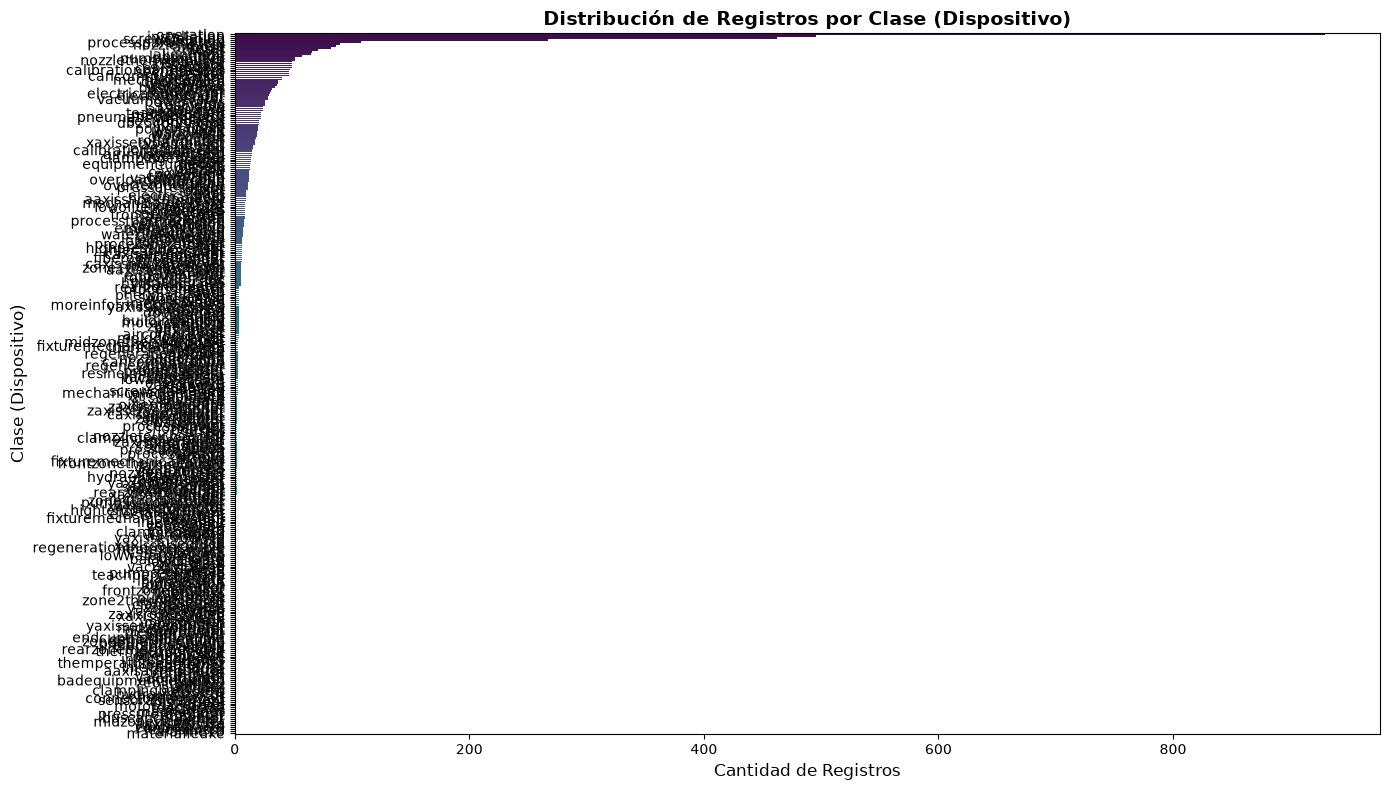

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener el conteo de registros por clase
conteo_clases = y.value_counts()

# 2. Configurar la figura del gráfico
plt.figure(figsize=(14, 8))

# Crear un gráfico de barras horizontales para leer bien los nombres de las clases
sns.barplot(
    x=conteo_clases.values, y=conteo_clases.index, palette='viridis', hue=conteo_clases.index, legend=False
)

# 3. Añadir títulos y etiquetas
plt.title(
    'Distribución de Registros por Clase (Dispositivo)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Clase (Dispositivo)', fontsize=12)

# Ajustar diseño para que no se corte nada
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Vamos a agrupar los dispositivos que solo aparecen menos de 25 veces

In [59]:
from sklearn.model_selection import train_test_split

# 1. Aplicar el umbral de 25 para la cola larga (agrupar en "otros")
UMBRAL_MINIMO = 25
conteo_clases = y.value_counts()
clases_raras = conteo_clases[conteo_clases < UMBRAL_MINIMO].index

y_agrupada = y.apply(lambda x: 'otros' if x in clases_raras else x)
y = y_agrupada

print(f"Número de clases finales (incluyendo 'otros'): {y.nunique()}")


Número de clases finales (incluyendo 'otros'): 38


In [60]:
## Esto es para borrar otros en caso de querer dejarlo eliminar este bloque 

# 1. Eliminar los registros que correspondan a 'otros' (tanto en X como en y)
mask = y.astype(str).str.lower().str.strip() != 'otros'

X = X[mask]
y = y[mask]

print(f"Total de registros tras eliminar 'otros': {len(y)}")
print(f"Número de clases restantes: {y.nunique()}")

Total de registros tras eliminar 'otros': 3743
Número de clases restantes: 37


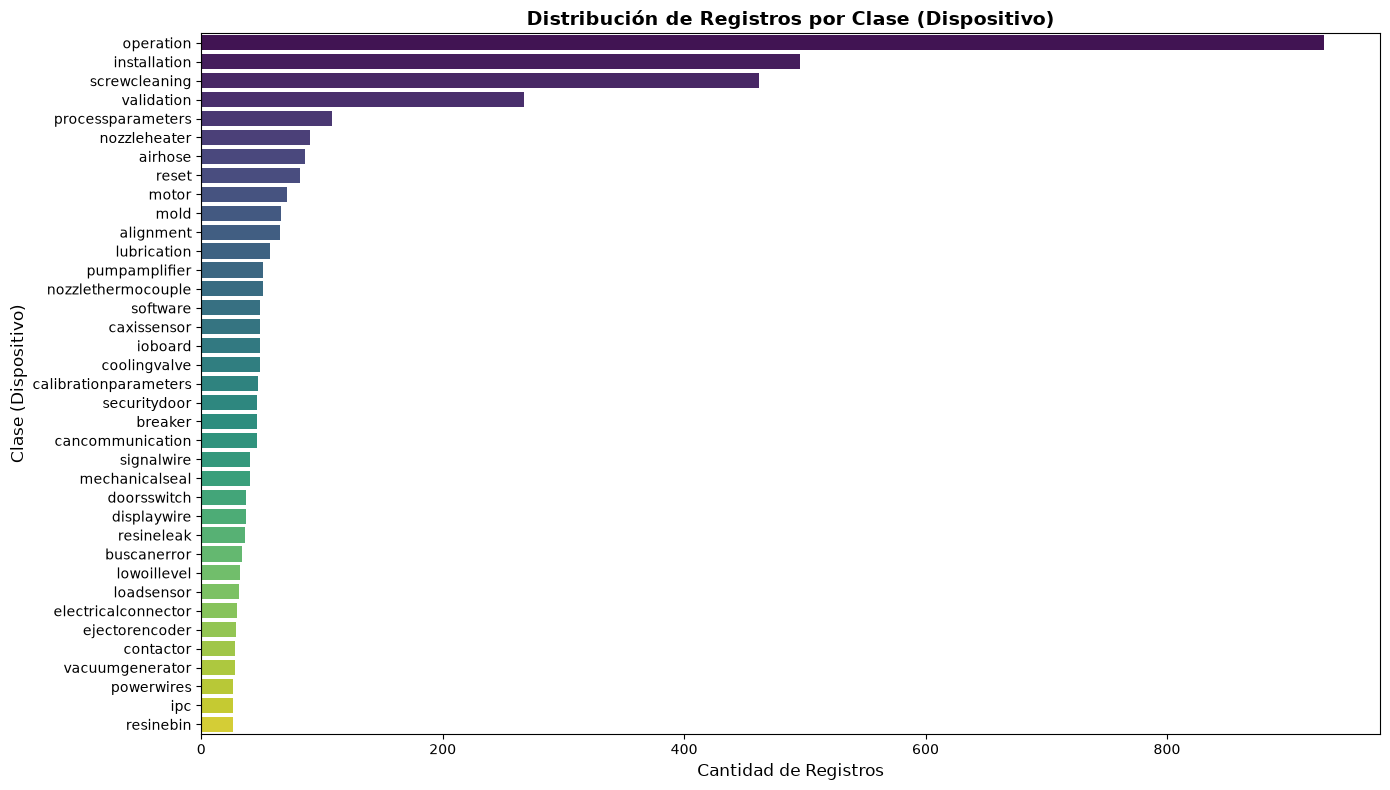

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener el conteo de registros por clase
conteo_clases = y.value_counts()

# 2. Configurar la figura del gráfico
plt.figure(figsize=(14, 8))

# Crear un gráfico de barras horizontales para leer bien los nombres de las clases
sns.barplot(
    x=conteo_clases.values, y=conteo_clases.index, palette='viridis', hue=conteo_clases.index, legend=False
)

# 3. Añadir títulos y etiquetas
plt.title(
    'Distribución de Registros por Clase (Dispositivo)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Clase (Dispositivo)', fontsize=12)

# Ajustar diseño para que no se corte nada
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Creamos 6 subclases en las cuales se agruparan los registros

In [62]:
# Extraer las clases únicas directamente desde tu 'y' filtrado
clases_reales = sorted(y.dropna().astype(str).str.lower().str.strip().unique())

print(f"Total de clases únicas en y: {len(clases_reales)}")
print("\nListado listo para tu diccionario:")
for cls in clases_reales:
    print(f"    '{cls}': 'Macro_Aqui_Asignar',")

Total de clases únicas en y: 37

Listado listo para tu diccionario:
    'airhose': 'Macro_Aqui_Asignar',
    'alignment': 'Macro_Aqui_Asignar',
    'breaker': 'Macro_Aqui_Asignar',
    'buscanerror': 'Macro_Aqui_Asignar',
    'calibrationparameters': 'Macro_Aqui_Asignar',
    'cancommunication': 'Macro_Aqui_Asignar',
    'caxissensor': 'Macro_Aqui_Asignar',
    'contactor': 'Macro_Aqui_Asignar',
    'coolingvalve': 'Macro_Aqui_Asignar',
    'displaywire': 'Macro_Aqui_Asignar',
    'doorsswitch': 'Macro_Aqui_Asignar',
    'ejectorencoder': 'Macro_Aqui_Asignar',
    'electricalconnector': 'Macro_Aqui_Asignar',
    'installation': 'Macro_Aqui_Asignar',
    'ioboard': 'Macro_Aqui_Asignar',
    'ipc': 'Macro_Aqui_Asignar',
    'loadsensor': 'Macro_Aqui_Asignar',
    'lowoillevel': 'Macro_Aqui_Asignar',
    'lubrication': 'Macro_Aqui_Asignar',
    'mechanicalseal': 'Macro_Aqui_Asignar',
    'mold': 'Macro_Aqui_Asignar',
    'motor': 'Macro_Aqui_Asignar',
    'nozzleheater': 'Macro_Aqui_Asign

In [63]:
# 1. Diccionario de mapeo experto para las 38 clases
class_to_macro = {
# 1. Mecánica, Hidráulica y Actuadores (Componentes Físicos)
    'airhose': 'Mecanica_Actuadores',
    'alignment': 'Mecanica_Actuadores',
    'breaker': 'Mecanica_Actuadores',
    'coolingvalve': 'Mecanica_Actuadores',
    'ejectorencoder': 'Mecanica_Actuadores',
    'lubrication': 'Mecanica_Actuadores',
    'mechanicalseal': 'Mecanica_Actuadores',
    'mold': 'Mecanica_Actuadores',
    'motor': 'Mecanica_Actuadores',
    'pumpamplifier': 'Mecanica_Actuadores',
    'screwcleaning': 'Mecanica_Actuadores',
    'vacuumgenerator': 'Mecanica_Actuadores',

    # 2. Electrónica, Control y Sensores (Sistema Eléctrico, Lógico y de Medición)
    'caxissensor': 'Electronica_Control_Sensores',
    'loadsensor': 'Electronica_Control_Sensores',
    'lowoillevel': 'Electronica_Control_Sensores',
    'nozzleheater': 'Electronica_Control_Sensores',
    'nozzlethermocouple': 'Electronica_Control_Sensores',
    'resinebin': 'Electronica_Control_Sensores',
    'resineleak': 'Electronica_Control_Sensores',
    'contactor': 'Electronica_Control_Sensores',
    'displaywire': 'Electronica_Control_Sensores',
    'doorsswitch': 'Electronica_Control_Sensores',
    'electricalconnector': 'Electronica_Control_Sensores',
    'ioboard': 'Electronica_Control_Sensores',
    'powerwires': 'Electronica_Control_Sensores',
    'securitydoor': 'Electronica_Control_Sensores',
    'signalwire': 'Electronica_Control_Sensores',
    'buscanerror': 'Electronica_Control_Sensores',
    'calibrationparameters': 'Electronica_Control_Sensores',
    'cancommunication': 'Electronica_Control_Sensores',
    'ipc': 'Electronica_Control_Sensores',
    'processparameters': 'Electronica_Control_Sensores',
    'reset': 'Electronica_Control_Sensores',
    'software': 'Electronica_Control_Sensores',
    'validation': 'Electronica_Control_Sensores',

    # 3. Operación y Procesos
    'installation': 'Operacion_Y_Proceso',
    'operation': 'Operacion_Y_Proceso',
    'otros': 'Operacion_Y_Proceso'
}

# 2. Crear y2 (o y_macro) mapeando las clases de tu 'y' actual
y_macro = pd.Series(y).astype(str).str.lower().str.strip().map(class_to_macro)

# Validar que no queden valores sin mapear
print(f"Registros sin mapear en y_macro: {y_macro.isnull().sum()}")



Registros sin mapear en y_macro: 0


In [64]:
import numpy as np

from transformers import Trainer, TrainingArguments, AutoTokenizer, AutoModelForSequenceClassification

# 2. Cargar el tokenizador de BETO
model_name = "dccuchile/bert-base-spanish-wwm-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 1. Calcular la longitud en caracteres
max_caracteres = max(len(str(texto)) for texto in X)
print(f"Longitud máxima en caracteres: {max_caracteres}")

# 2. Calcular la longitud real en tokens usando el tokenizador de BETO
tokens_lengths = [len(tokenizer.tokenize(str(texto))) for texto in X]
print(f"Longitud máxima absoluta en tokens: {max(tokens_lengths)}")

# 3. Ver percentiles clave (muy útil para descartar outliers gigantes y ahorrar memoria/GPU)
print(f"Percentil 95 de tokens: {int(np.percentile(tokens_lengths, 95))}")
print(f"Percentil 99 de tokens: {int(np.percentile(tokens_lengths, 99))}")

Longitud máxima en caracteres: 827
Longitud máxima absoluta en tokens: 186
Percentil 95 de tokens: 52
Percentil 99 de tokens: 82


### Dividimos el dataset entre entrenamiento, validacion y test con 70 -30

In [65]:
# 3. División 70/30 conservando tu X, y (sub-clases) y la nueva y_macro (clase padre)
X_train_val, X_test, y_macro_train_val, y_macro_test, y_sub_train_val, y_sub_test = train_test_split(
    X, y_macro, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y_macro
)

print(f"\nDimensiones de los conjuntos:")
print(f"- Entrenamiento y Validación (70%): {X_train_val.shape[0]} registros")
print(f"- Prueba Final (30%):              {X_test.shape[0]} registros")


Dimensiones de los conjuntos:
- Entrenamiento y Validación (70%): 2620 registros
- Prueba Final (30%):              1123 registros


### Hazemos un primer modelo para encontrar la categoria general

Usamos TF'IDF para este

In [66]:
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import numpy as np

# Listas para acumular las etiquetas reales y las predichas del Nivel 1
y_true_macro_all = []
y_pred_macro_all = []

# Configuramos K-Fold estratificado usando las macro-etiquetas (Nivel 1)
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Generando validación cruzada (3-Fold) para el Nivel 1 (Macro-Categorías)...\n")

for train_idx, val_idx in kf.split(X_train_val, y_macro_train_val):
    X_f_train = X_train_val.iloc[train_idx]
    y_f_train = y_macro_train_val.iloc[train_idx]
    
    X_f_val = X_train_val.iloc[val_idx]
    y_f_val = y_macro_train_val.iloc[val_idx]

    # Vectorización independiente por fold para evitar data leakage
    tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
    X_f_train_tfidf = tfidf.fit_transform(X_f_train)
    X_f_val_tfidf = tfidf.transform(X_f_val)

    # Entrenar modelo para Nivel 1 con pesos balanceados
    model_macro = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model_macro.fit(X_f_train_tfidf, y_f_train)

    # Predecir en el fold de validación actual
    y_pred = model_macro.predict(X_f_val_tfidf)
    
    # Acumular resultados
    y_true_macro_all.extend(y_f_val)
    y_pred_macro_all.extend(y_pred)

# Imprimir el reporte detallado del Nivel 1
print("="*65)
print("REPORTE DE CLASIFICACIÓN - NIVEL 1 (Macro-Categorías / 3-Fold CV)")
print("="*65)
print(classification_report(y_true_macro_all, y_pred_macro_all, zero_division=0))

Generando validación cruzada (3-Fold) para el Nivel 1 (Macro-Categorías)...

REPORTE DE CLASIFICACIÓN - NIVEL 1 (Macro-Categorías / 3-Fold CV)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.66      0.77      0.71       887
         Mecanica_Actuadores       0.82      0.74      0.78       735
         Operacion_Y_Proceso       0.74      0.68      0.71       998

                    accuracy                           0.73      2620
                   macro avg       0.74      0.73      0.73      2620
                weighted avg       0.73      0.73      0.73      2620



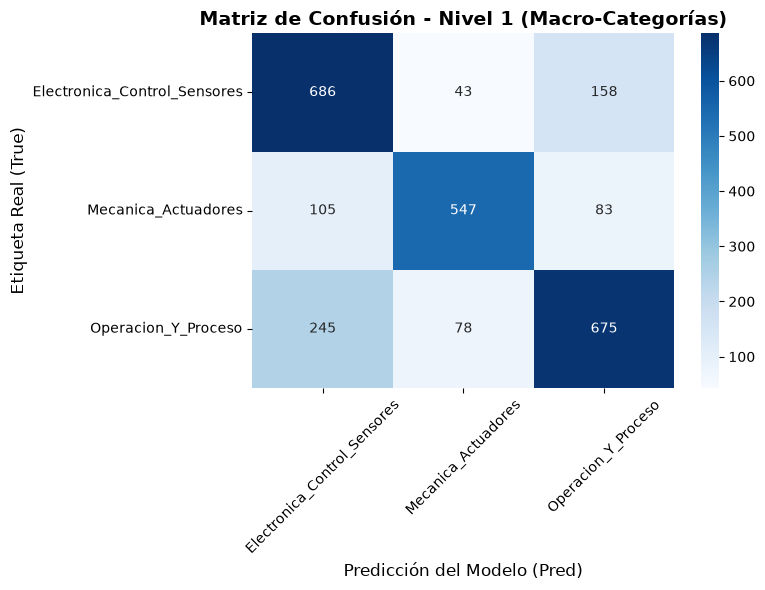

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Obtener las etiquetas únicas ordenadas alfabéticamente
labels = sorted(list(set(y_true_macro_all)))

# Calcular la matriz de confusión
cm = confusion_matrix(y_true_macro_all, y_pred_macro_all, labels=labels)

# Graficar con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicción del Modelo (Pred)', fontsize=12)
plt.ylabel('Etiqueta Real (True)', fontsize=12)
plt.title('Matriz de Confusión - Nivel 1 (Macro-Categorías)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Optimizamos el modelo

In [68]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Definir el Pipeline combinando características de texto y clasificación
pipeline_macro = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 3), max_df=0.9)),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# 2. Definir la rejilla de hiperparámetros a evaluar (en este caso, la fuerza de regularización C)
param_grid = {
    'clf__C': [0.1, 1.0,2.0,3.0,4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 15.0, 20.0, 25.0, 30.0]
}

# 3. Configurar GridSearchCV con validación cruzada de 3 pliegues
grid_search = GridSearchCV(
    estimator=pipeline_macro,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

print("Optimizando hiperparámetros para el Nivel 1...")
grid_search.fit(X_train_val, y_macro_train_val)

print(f"\n✅ Mejores hiperparámetros encontrados: {grid_search.best_params_}")
print(f"✅ Mejor F1-Macro obtenido en validación: {grid_search.best_score_:.4f}")

# Guardar el mejor modelo optimizado del Nivel 1
mejor_modelo_nivel1 = grid_search.best_estimator_

Optimizando hiperparámetros para el Nivel 1...

✅ Mejores hiperparámetros encontrados: {'clf__C': 6.0}
✅ Mejor F1-Macro obtenido en validación: 0.7503


### Pasamos a provar con un SVC

REPORTE DE PRUEBA - NIVEL 1 (LinearSVC en X_test)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.71      0.81      0.75       380
         Mecanica_Actuadores       0.85      0.79      0.82       315
         Operacion_Y_Proceso       0.75      0.70      0.72       428

                    accuracy                           0.76      1123
                   macro avg       0.77      0.76      0.76      1123
                weighted avg       0.76      0.76      0.76      1123



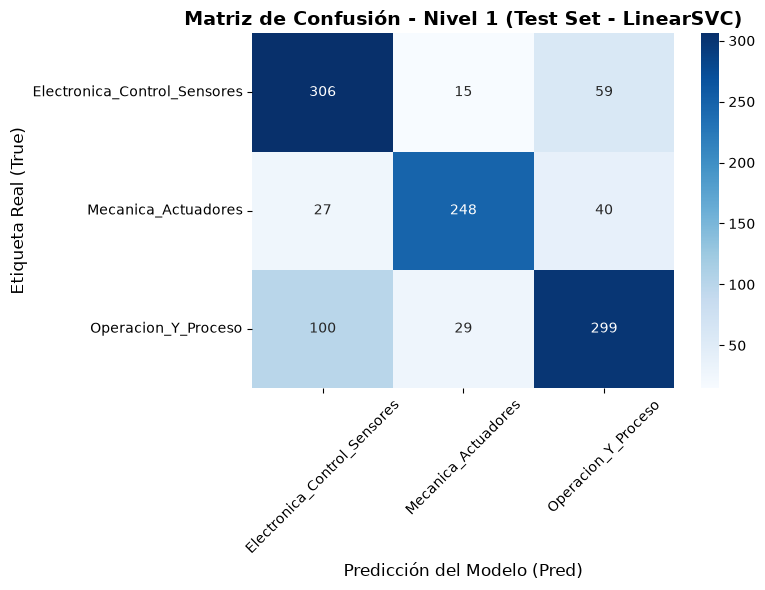

In [69]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. EVALUACIÓN REAL DEL NIVEL 1 EN TEST
# ==========================================
y_pred_macro_test = mejor_modelo_nivel1.predict(X_test)

print("="*65)
print("REPORTE DE PRUEBA - NIVEL 1 (LinearSVC en X_test)")
print("="*65)
print(classification_report(y_macro_test, y_pred_macro_test, zero_division=0))

# Matriz de confusión para el Nivel 1 en Test
labels_macro = sorted(list(y_macro_test.unique()))
cm_test = confusion_matrix(y_macro_test, y_pred_macro_test, labels=labels_macro)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', xticklabels=labels_macro, yticklabels=labels_macro)
plt.xlabel('Predicción del Modelo (Pred)', fontsize=12)
plt.ylabel('Etiqueta Real (True)', fontsize=12)
plt.title('Matriz de Confusión - Nivel 1 (Test Set - LinearSVC)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [70]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# 1. Pipeline con opciones amplias para TF-IDF y LinearSVC
pipeline_tuning = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=15000, max_df=0.9)),
    ('clf', LinearSVC(class_weight='balanced', random_state=42, max_iter=5000))
])

# 2. Rejilla de hiperparámetros extendida
param_grid_expanded = {
    'tfidf__ngram_range': [(1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3],
    'tfidf__sublinear_tf': [True, False],  # Escala logarítmica de la frecuencia de términos
    'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    'clf__loss': ['hinge', 'squared_hinge'] # Probar diferentes funciones de pérdida
}

# 3. Configuración del GridSearchCV
grid_search_fin = GridSearchCV(
    estimator=pipeline_tuning,
    param_grid=param_grid_expanded,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

print("Iniciando búsqueda exhaustiva de hiperparámetros para el Nivel 1...")
grid_search_fin.fit(X_train_val, y_macro_train_val)

print(f"\n✅ Mejores hiperparámetros encontrados: {grid_search_fin.best_params_}")
print(f"✅ Mejor F1-Macro obtenido en validación cruzada: {grid_search_fin.best_score_:.4f}")

# Actualizar el mejor modelo del Nivel 1
mejor_modelo_nivel1 = grid_search_fin.best_estimator_

# Evaluar la configuración ganadora en el conjunto de prueba
y_pred_test_optimized = mejor_modelo_nivel1.predict(X_test)

print("="*65)
print("REPORTE DE PRUEBA FINAL - NIVEL 1 OPTIMIZADO")
print("="*65)
print(classification_report(y_macro_test, y_pred_test_optimized, zero_division=0))

Iniciando búsqueda exhaustiva de hiperparámetros para el Nivel 1...
Fitting 3 folds for each of 168 candidates, totalling 504 fits

✅ Mejores hiperparámetros encontrados: {'clf__C': 0.5, 'clf__loss': 'squared_hinge', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
✅ Mejor F1-Macro obtenido en validación cruzada: 0.7541
REPORTE DE PRUEBA FINAL - NIVEL 1 OPTIMIZADO
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.71      0.81      0.75       380
         Mecanica_Actuadores       0.86      0.77      0.81       315
         Operacion_Y_Proceso       0.75      0.71      0.73       428

                    accuracy                           0.76      1123
                   macro avg       0.77      0.76      0.77      1123
                weighted avg       0.77      0.76      0.76      1123



### Utilizamos beto para conseguir la primera categoria

In [71]:
import torch
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import classification_report, accuracy_score

# 1. Codificar las etiquetas de texto a enteros (0 al 4)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_macro_train_val)
y_test_encoded = label_encoder.transform(y_macro_test)

# Guardar las clases originales para mapearlas después
target_names = label_encoder.classes_
num_labels = len(target_names)
print(f"Clases a clasificar en Nivel 1: {target_names}")

# 2. Cargar el tokenizador de BETO
model_name = "dccuchile/bert-base-spanish-wwm-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 3. Tokenizar los conjuntos de entrenamiento/validación y prueba
# Usamos max_length=128 ya que los reportes de mantenimiento suelen ser cortos
train_encodings = tokenizer(list(X_train_val), truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(list(X_test), truncation=True, padding=True, max_length=128)

# Crear Dataset de PyTorch personalizado
class MaintenanceDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = MaintenanceDataset(train_encodings, y_train_encoded)
test_dataset = MaintenanceDataset(test_encodings, y_test_encoded)

Clases a clasificar en Nivel 1: ['Electronica_Control_Sensores' 'Mecanica_Actuadores'
 'Operacion_Y_Proceso']


In [72]:
# 1. Cargar el modelo base de BETO adaptado para clasificación de N clases
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_labels)

# 2. Definir métricas de evaluación para el Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}

# 3. Configurar los argumentos de entrenamiento
# 3. Configurar los argumentos de entrenamiento (sin warmup_ratio para evitar el error de versión)
# 3. Configurar los argumentos de entrenamiento de forma minimalista y compatible
training_args = TrainingArguments(
    output_dir='./results_beto_nivel1',          # Directorio para guardar checkpoints
    num_train_epochs=6,                          # Épocas de entrenamiento
    per_device_train_batch_size=16,              # Tamaño de lote para entrenamiento
    per_device_eval_batch_size=16,               # Tamaño de lote para evaluación
    learning_rate=2e-5,                          # Tasa de aprendizaje estándar para BERT
    weight_decay=0.01,
    save_strategy="epoch",                       # Guardar checkpoint al finalizar cada época
)

# 4. Inicializar el Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    compute_metrics=compute_metrics,
)

print("Iniciando fine-tuning de BETO para el Nivel 1...")
trainer.train()
print("✅ ¡Entrenamiento de BETO finalizado!")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 16358.38it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from differe

Iniciando fine-tuning de BETO para el Nivel 1...


Step,Training Loss
500,0.569910


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.52it/s]


✅ ¡Entrenamiento de BETO finalizado!


REPORTE DE PRUEBA - NIVEL 1 (BETO en X_test)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.72      0.76      0.74       380
         Mecanica_Actuadores       0.80      0.82      0.81       315
         Operacion_Y_Proceso       0.76      0.71      0.73       428

                    accuracy                           0.76      1123
                   macro avg       0.76      0.76      0.76      1123
                weighted avg       0.76      0.76      0.76      1123



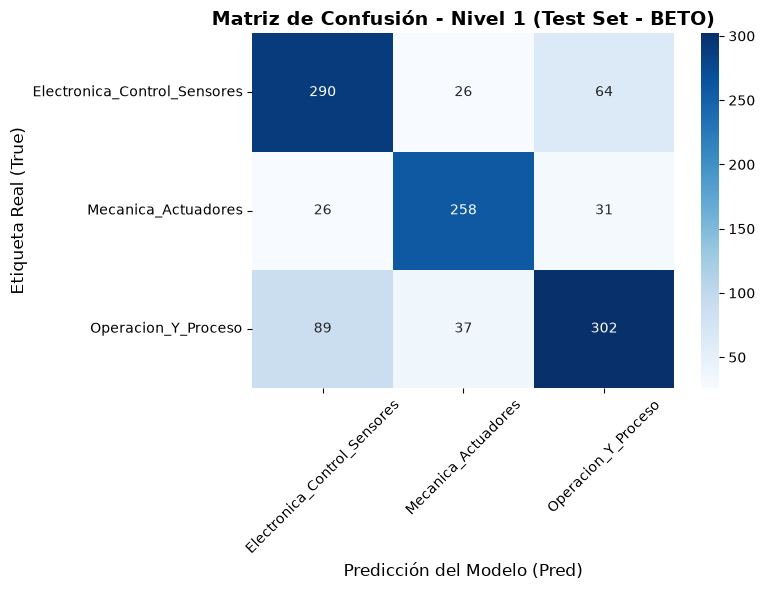

In [73]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Realizar predicciones sobre el conjunto de prueba (test_dataset)
predictions_output = trainer.predict(test_dataset)
y_pred_logits = predictions_output.predictions
y_pred_encoded = np.argmax(y_pred_logits, axis=1)

# 2. Convertir las predicciones numéricas de vuelta a los nombres originales de las macro-categorías
y_pred_beto = label_encoder.inverse_transform(y_pred_encoded)

# ==========================================
# REPORTE DE CLASIFICACIÓN FINAL - NIVEL 1 (BETO)
# ==========================================
print("="*65)
print("REPORTE DE PRUEBA - NIVEL 1 (BETO en X_test)")
print("="*65)
print(classification_report(y_macro_test, y_pred_beto, zero_division=0))

# 3. Generar y graficar la matriz de confusión para ver el comportamiento detallado
labels_macro = sorted(list(y_macro_test.unique()))
cm_beto = confusion_matrix(y_macro_test, y_pred_beto, labels=labels_macro)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_beto, annot=True, fmt='d', cmap='Blues', xticklabels=labels_macro, yticklabels=labels_macro)
plt.xlabel('Predicción del Modelo (Pred)', fontsize=12)
plt.ylabel('Etiqueta Real (True)', fontsize=12)
plt.title('Matriz de Confusión - Nivel 1 (Test Set - BETO)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Ajuste fino en BETO

In [74]:
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
from transformers import Trainer, TrainingArguments
import numpy as np

# 1. Codificar etiquetas y calcular los pesos de clase automáticamente
label_encoder_3g = LabelEncoder()
y_train_encoded_3g = label_encoder_3g.fit_transform(y_macro_train_val)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_encoded_3g), 
    y=y_train_encoded_3g
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(model.device)

print("Pesos de clase calculados correctamente:", weights_tensor)

# 2. Crear un Trainer personalizado con la firma actualizada (aceptando **kwargs)
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        # Aplicar CrossEntropyLoss ponderada por clase
        loss_fct = nn.CrossEntropyLoss(weight=weights_tensor)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

# 3. Configurar los argumentos con Cosine Scheduler
training_args_advanced = TrainingArguments(
    output_dir='./results_beto_advanced',
    num_train_epochs=5,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    lr_scheduler_type="cosine",       # Decaimiento en coseno suave
    weight_decay=0.01,
    eval_strategy="no",
    save_strategy="no",
)

# 4. Instanciar el Trainer avanzado
trainer_advanced = WeightedTrainer(
    model=model,
    args=training_args_advanced,
    train_dataset=train_dataset,
)

print("Iniciando entrenamiento avanzado de BETO...")
trainer_advanced.train()
print("✅ ¡Entrenamiento avanzado finalizado!")

Pesos de clase calculados correctamente: tensor([0.9846, 1.1882, 0.8751], device='cuda:0')
Iniciando entrenamiento avanzado de BETO...


Step,Training Loss
500,0.116894


✅ ¡Entrenamiento avanzado finalizado!


REPORTE DE PRUEBA - BETO AVANZADO (Pesos de Clase + Cosine Scheduler)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.71      0.75      0.73       380
         Mecanica_Actuadores       0.83      0.78      0.81       315
         Operacion_Y_Proceso       0.75      0.75      0.75       428

                    accuracy                           0.76      1123
                   macro avg       0.76      0.76      0.76      1123
                weighted avg       0.76      0.76      0.76      1123



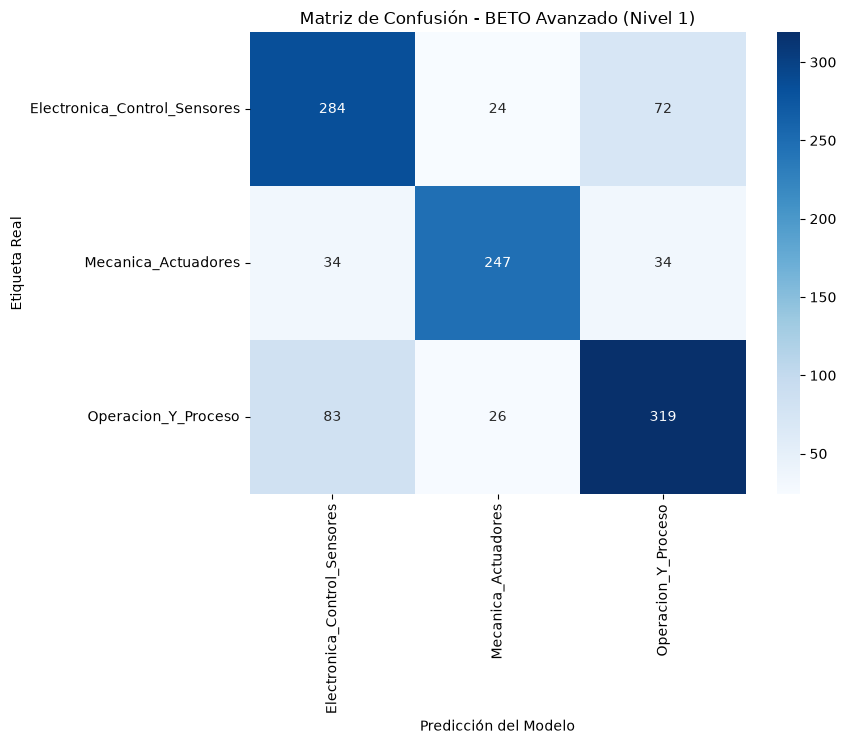

In [75]:
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Obtener predicciones del modelo avanzado en el conjunto de prueba
preds_output = trainer_advanced.predict(test_dataset)
logits = torch.tensor(preds_output.predictions)
probs = F.softmax(logits, dim=-1).numpy()

# 2. Obtener la clase con mayor probabilidad
y_pred_encoded_advanced = np.argmax(probs, axis=1)

# 3. Decodificar las predicciones a texto original
y_pred_advanced = label_encoder_3g.inverse_transform(y_pred_encoded_advanced)

# 4. Mostrar el reporte de clasificación detallado
print("="*65)
print("REPORTE DE PRUEBA - BETO AVANZADO (Pesos de Clase + Cosine Scheduler)")
print("="*65)
print(classification_report(y_macro_test, y_pred_advanced, zero_division=0))

# 5. Opcional: Graficar la nueva matriz de confusión
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_macro_test, y_pred_advanced, labels=label_encoder_3g.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder_3g.classes_, 
            yticklabels=label_encoder_3g.classes_)
plt.title("Matriz de Confusión - BETO Avanzado (Nivel 1)")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Etiqueta Real")
plt.show()

Combinacion BETO y Linear SVC

In [76]:
from sklearn.feature_extraction.text import TfidfVectorizer
import nltk

# Asegúrate de tener las stopwords de NLTK descargadas
try:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    stop_words_es = list(stopwords.words('spanish'))
except:
    stop_words_es = 'spanish'

# Palabras genéricas de mantenimiento que aparecen en casi todos lados y no discriminan clase
custom_stops = ['equipo', 'maquina', 'falla', 'reparacion', 'trabajo', 'realizo', 'dia', 'se']
if isinstance(stop_words_es, list):
    stop_words_es.extend(custom_stops)

# Inicializar y ajustar el vectorizador TF-IDF optimizado
tfidf_vectorizer = TfidfVectorizer(
    max_features=8000,           # Ampliamos el vocabulario para capturar mejor la jerga
    ngram_range=(1, 3),          # Unigramas, bigramas y trigramas
    min_df=2,                    # Elimina palabras únicas / errores de dedo
    max_df=0.85,                 # Elimina palabras demasiado comunes (ruido)
    sublinear_tf=True,           # Escalamiento logarítmico de frecuencias
    stop_words=stop_words_es     # Stopwords en español + jerga técnica vacía
)

X_train_vectorized = tfidf_vectorizer.fit_transform(X_train_val)
X_test_vectorized = tfidf_vectorizer.transform(X_test)

print("¡Matrices TF-IDF optimizadas creadas exitosamente!")
print(f"Nuevas dimensiones de X_train_vectorized: {X_train_vectorized.shape}")

¡Matrices TF-IDF optimizadas creadas exitosamente!
Nuevas dimensiones de X_train_vectorized: (2620, 5213)


In [77]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
import torch.nn.functional as F
import numpy as np

# 1. Obtener las probabilidades (logits pasados por softmax) del modelo BETO avanzado en el test set
preds_output = trainer_advanced.predict(test_dataset)
logits_beto = torch.tensor(preds_output.predictions)
probs_beto = F.softmax(logits_beto, dim=-1).numpy()

# 2. Entrenar un LinearSVC calibrado para que devuelva probabilidades estandarizadas
base_svc = LinearSVC(C=7.0, random_state=42) # Usando el mejor hiperparámetro que encontraste antes
calibrated_svc = CalibratedClassifierCV(base_svc, cv=3)
calibrated_svc.fit(X_train_vectorized, y_train_encoded_3g)

# Obtener probabilidades de LinearSVC
probs_svc = calibrated_svc.predict_proba(X_test_vectorized)

# 3. Ensamblaje por Votación Suave (Soft Voting)
# Damos un peso mayor a BETO (ej. 60%) por su comprensión semántica, y 40% a LinearSVC
alpha = 0.75 
probs_ensemble = (alpha * probs_beto) + ((1 - alpha) * probs_svc)

# 4. Obtener las predicciones finales del ensamble
y_pred_encoded_ensemble = np.argmax(probs_ensemble, axis=1)
y_pred_ensemble = label_encoder_3g.inverse_transform(y_pred_encoded_ensemble)

# 5. Evaluar el resultado final combinado
from sklearn.metrics import classification_report
print("="*65)
print("REPORTE DE PRUEBA - ENSAMBLE HÍBRIDO (BETO + LinearSVC)")
print("="*65)
print(classification_report(y_macro_test, y_pred_ensemble, zero_division=0))

REPORTE DE PRUEBA - ENSAMBLE HÍBRIDO (BETO + LinearSVC)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.71      0.75      0.73       380
         Mecanica_Actuadores       0.84      0.79      0.81       315
         Operacion_Y_Proceso       0.75      0.75      0.75       428

                    accuracy                           0.76      1123
                   macro avg       0.77      0.76      0.76      1123
                weighted avg       0.76      0.76      0.76      1123



### Marcamos un  treshold de probabilidades de la clase general y en caso de estar debajo de este se mandaran a un modelo generico con todas las clases.

In [78]:
import numpy as np
from sklearn.metrics import classification_report

# Definir el umbral de confianza de 90%
THRESHOLD = 0.90

# 1. Obtener la probabilidad máxima y la clase predicha para cada muestra en el test set
max_probs = np.max(probs_ensemble, axis=1)
y_pred_encoded_raw = np.argmax(probs_ensemble, axis=1)
y_pred_raw = label_encoder_3g.inverse_transform(y_pred_encoded_raw)

# 2. Aplicar la lógica del umbral de confianza
y_pred_con_umbral = []
for pred, prob in zip(y_pred_raw, max_probs):
    if prob >= THRESHOLD:
        y_pred_con_umbral.append(pred)
    else:
        y_pred_con_umbral.append("Revision_Manual_General") # Modelo general / Respaldo

y_pred_con_umbral = np.array(y_pred_con_umbral)

# 3. Estadísticas del filtrado
total_samples = len(y_macro_test)
manual_count = np.sum(y_pred_con_umbral == "Revision_Manual_General")
automated_count = total_samples - manual_count

print("="*65)
print("ESTADÍSTICAS DE ENRUTAMIENTO POR CONFIANZA")
print("="*65)
print(f"Total de registros evaluados: {total_samples}")
print(f"✔ Automatizados (Confianza >= {THRESHOLD}): {automated_count} ({automated_count/total_samples*100:.1f}%)")
print(f"⚠️ Enviados a Revisión General/Manual (< {THRESHOLD}): {manual_count} ({manual_count/total_samples*100:.1f}%)")

# 4. Evaluar la precisión real únicamente en los casos automatizados con éxito
mask_auto = y_pred_con_umbral != "Revision_Manual_General"
if np.sum(mask_auto) > 0:
    print("\n" + "="*65)
    print(f"REPORTE DE PRUEBA - SOLO CASOS AUTOMATIZADOS (Con Criterio de Certeza)")
    print("="*65)
    print(classification_report(y_macro_test[mask_auto], y_pred_con_umbral[mask_auto], zero_division=0))

ESTADÍSTICAS DE ENRUTAMIENTO POR CONFIANZA
Total de registros evaluados: 1123
✔ Automatizados (Confianza >= 0.9): 631 (56.2%)
⚠️ Enviados a Revisión General/Manual (< 0.9): 492 (43.8%)

REPORTE DE PRUEBA - SOLO CASOS AUTOMATIZADOS (Con Criterio de Certeza)
                              precision    recall  f1-score   support

Electronica_Control_Sensores       0.84      0.88      0.86       194
         Mecanica_Actuadores       0.97      0.90      0.93       197
         Operacion_Y_Proceso       0.87      0.88      0.87       240

                    accuracy                           0.89       631
                   macro avg       0.89      0.89      0.89       631
                weighted avg       0.89      0.89      0.89       631



### Desarrollamos modelos especificos para cada grupo

### Modelo base LinearSVC

In [79]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# 1. Crear DataFrames unificados de entrenamiento y prueba con sus sub-clases (etiquetas finas)
# Asegúrate de que y_sub_train_val e y_sub_test contengan las sub-categorías originales detalladas
df_train = pd.DataFrame({
    'texto': X_train_val,
    'macro': y_macro_train_val,
    'subclase': y_sub_train_val
})

df_test = pd.DataFrame({
    'texto': X_test,
    'macro': y_macro_test,
    'subclase': y_sub_test
})

# 2. Filtrar exclusivamente los registros pertenecientes a Mecánica de Actuadores
df_mecanica_train = df_train[df_train['macro'] == 'Mecanica_Actuadores']
df_mecanica_test = df_test[df_test['macro'] == 'Mecanica_Actuadores']

print(f"Registros de entrenamiento para Mecánica: {len(df_mecanica_train)}")
print(f"Registros de prueba para Mecánica: {len(df_mecanica_test)}")
print("\nSub-clases a clasificar en este especialista:")
print(df_mecanica_train['subclase'].value_counts())

# 3. Vectorización TF-IDF específica para el vocabulario mecánico
vectorizer_mecanica = TfidfVectorizer(
    max_features=4000,
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True
)

X_train_mec = vectorizer_mecanica.fit_transform(df_mecanica_train['texto'])
X_test_mec = vectorizer_mecanica.transform(df_mecanica_test['texto'])

y_train_mec = df_mecanica_train['subclase']
y_test_mec = df_mecanica_test['subclase']

# 4. Entrenar el modelo especialista (LinearSVC optimizado para sub-clases)
especialista_mecanica = LinearSVC(C=3.0, random_state=42, class_weight='balanced')
especialista_mecanica.fit(X_train_mec, y_train_mec)

# 5. Evaluar el rendimiento del especialista en su propio dominio
y_pred_mec = especialista_mecanica.predict(X_test_mec)

print("\n" + "="*65)
print("REPORTE DE ESPECIALISTA - NIVEL 2: MECÁNICA DE ACTUADORES")
print("="*65)
print(classification_report(y_test_mec, y_pred_mec, zero_division=0))

Registros de entrenamiento para Mecánica: 735
Registros de prueba para Mecánica: 315

Sub-clases a clasificar en este especialista:
subclase
screwcleaning      331
airhose             61
motor               52
alignment           45
mold                43
lubrication         37
breaker             33
coolingvalve        33
pumpamplifier       32
mechanicalseal      29
ejectorencoder      22
vacuumgenerator     17
Name: count, dtype: int64

REPORTE DE ESPECIALISTA - NIVEL 2: MECÁNICA DE ACTUADORES
                 precision    recall  f1-score   support

        airhose       0.92      0.92      0.92        25
      alignment       0.94      0.85      0.89        20
        breaker       0.73      0.85      0.79        13
   coolingvalve       0.87      0.81      0.84        16
 ejectorencoder       1.00      1.00      1.00         7
    lubrication       0.84      0.80      0.82        20
 mechanicalseal       0.62      0.91      0.74        11
           mold       0.83      0.83     

In [80]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# ==========================================
# 1. ESPECIALISTA: ELECTRÓNICA Y CONTROL
# ==========================================
df_elec_train = df_train[df_train['macro'] == 'Electronica_Control_Sensores']
df_elec_test = df_test[df_test['macro'] == 'Electronica_Control_Sensores']

print("="*65)
print("ENTRENANDO ESPECIALISTA - NIVEL 2: ELECTRÓNICA Y CONTROL")
print("="*65)
print(f"Entrenamiento: {len(df_elec_train)} registros | Prueba: {len(df_elec_test)} registros")

vectorizer_elec = TfidfVectorizer(max_features=4000, ngram_range=(1, 3), min_df=2, sublinear_tf=True)
X_train_elec = vectorizer_elec.fit_transform(df_elec_train['texto'])
X_test_elec = vectorizer_elec.transform(df_elec_test['texto'])

y_train_elec = df_elec_train['subclase']
y_test_elec = df_elec_test['subclase']

especialista_elec = LinearSVC(C=3.0, random_state=42, class_weight='balanced')
especialista_elec.fit(X_train_elec, y_train_elec)
y_pred_elec = especialista_elec.predict(X_test_elec)

print(classification_report(y_test_elec, y_pred_elec, zero_division=0))


ENTRENANDO ESPECIALISTA - NIVEL 2: ELECTRÓNICA Y CONTROL
Entrenamiento: 887 registros | Prueba: 380 registros
                       precision    recall  f1-score   support

          buscanerror       0.08      0.12      0.10         8
calibrationparameters       0.52      0.72      0.60        18
     cancommunication       0.14      0.25      0.18         8
          caxissensor       0.82      0.69      0.75        13
            contactor       0.67      0.40      0.50        10
          displaywire       0.86      0.43      0.57        14
          doorsswitch       0.86      0.75      0.80         8
  electricalconnector       0.00      0.00      0.00         6
              ioboard       0.45      0.29      0.36        17
                  ipc       0.25      0.50      0.33         4
           loadsensor       0.58      1.00      0.74         7
          lowoillevel       0.70      0.78      0.74         9
         nozzleheater       0.62      0.62      0.62        34
   nozz

In [81]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

# 1. Filtrar los datos exclusivos de Electrónica y Control
df_elec_train = df_train[df_train['macro'] == 'Electronica_Control_Sensores'].reset_index(drop=True)
df_elec_test = df_test[df_test['macro'] == 'Electronica_Control_Sensores'].reset_index(drop=True)

print("="*65)
print("ENTRENANDO ESPECIALISTA HÍBRIDO (BETO + LINEARSVC) - NIVEL 2: ELECTRÓNICA")
print("="*65)

# Codificar las sub-clases a números
label_encoder_elec = LabelEncoder()
y_train_elec_enc = label_encoder_elec.fit_transform(df_elec_train['subclase'])
y_test_elec_enc = label_encoder_elec.transform(df_elec_test['subclase'])

# ==========================================
# RAMA A: LinearSVC + TF-IDF Optimizado
# ==========================================
vectorizer_elec = TfidfVectorizer(max_features=4000, ngram_range=(1, 3), min_df=2, sublinear_tf=True)
X_train_elec_vec = vectorizer_elec.fit_transform(df_elec_train['texto'])
X_test_elec_vec = vectorizer_elec.transform(df_elec_test['texto'])

base_svc_elec = LinearSVC(C=2.0, random_state=42, class_weight='balanced')
base_svc_elec.fit(X_train_elec_vec, y_train_elec_enc)
calibrated_svc_elec = CalibratedClassifierCV(base_svc_elec, cv=3)
calibrated_svc_elec.fit(X_train_elec_vec, y_train_elec_enc)

probs_svc_elec = calibrated_svc_elec.predict_proba(X_test_elec_vec)

# ==========================================
# RAMA B: BETO Especialista para Sub-clases
# ==========================================
model_ckpt = "dccuchile/bert-base-spanish-wwm-uncased" # O tu modelo base BETO
tokenizer_elec = AutoTokenizer.from_pretrained(model_ckpt)

def tokenize_elec(batch):
    return tokenizer_elec(batch['texto'], truncation=True, padding=True, max_length=128)

# Crear Dataset de Hugging Face
from datasets import Dataset
train_ds_elec = Dataset.from_pandas(df_elec_train.rename(columns={'subclase': 'label_text'}))
# Asignar etiquetas numéricas
train_ds_elec = train_ds_elec.add_column("label", y_train_elec_enc)
train_tokenized_elec = train_ds_elec.map(tokenize_elec, batched=True)

test_ds_elec = Dataset.from_pandas(df_elec_test.rename(columns={'subclase': 'label_text'}))
test_ds_elec = test_ds_elec.add_column("label", y_test_elec_enc)
test_tokenized_elec = test_ds_elec.map(tokenize_elec, batched=True)

model_elec = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt, 
    num_labels=len(label_encoder_elec.classes_)
)

args_elec = TrainingArguments(
    output_dir="./results_especialista_elec",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=6,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    save_strategy="epoch"
)

trainer_elec = Trainer(
    model=model_elec,
    args=args_elec,
    train_dataset=train_tokenized_elec,
    eval_dataset=test_tokenized_elec,
    # tokenizer=tokenizer_elec  <-- Elimina o comenta esta línea
)

print("\nEntrenando modelo BETO especialista...")
trainer_elec.train()

# Obtener probabilidades de BETO
preds_elec_output = trainer_elec.predict(test_tokenized_elec)
logits_beto_elec = torch.tensor(preds_elec_output.predictions)
probs_beto_elec = F.softmax(logits_beto_elec, dim=-1).numpy()

# ==========================================
# FUSIÓN: Soft Voting (BETO + LinearSVC)
# ==========================================
alpha = 0.6  # 60% BETO, 40% SVC
probs_ensemble_elec = (alpha * probs_beto_elec) + ((1 - alpha) * probs_svc_elec)

y_pred_enc_elec = np.argmax(probs_ensemble_elec, axis=1)
y_pred_final_elec = label_encoder_elec.inverse_transform(y_pred_enc_elec)

print("\n" + "="*65)
print("REPORTE DE ESPECIALISTA HÍBRIDO (BETO + SVC) - ELECTRÓNICA")
print("="*65)
print(classification_report(df_elec_test['subclase'], y_pred_final_elec, zero_division=0))

ENTRENANDO ESPECIALISTA HÍBRIDO (BETO + LINEARSVC) - NIVEL 2: ELECTRÓNICA


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 3388.37it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from differ


Entrenando modelo BETO especialista...


Epoch,Training Loss,Validation Loss
1,2.594398,2.543236
2,2.057669,2.015651
3,1.491869,1.849917
4,1.232357,1.713041
5,1.074843,1.716280
6,0.862350,1.724527


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.10s/it]



REPORTE DE ESPECIALISTA HÍBRIDO (BETO + SVC) - ELECTRÓNICA
                       precision    recall  f1-score   support

          buscanerror       0.00      0.00      0.00         8
calibrationparameters       0.57      0.67      0.62        18
     cancommunication       0.18      0.25      0.21         8
          caxissensor       0.79      0.85      0.81        13
            contactor       1.00      0.20      0.33        10
          displaywire       0.80      0.29      0.42        14
          doorsswitch       0.71      0.62      0.67         8
  electricalconnector       0.00      0.00      0.00         6
              ioboard       0.53      0.47      0.50        17
                  ipc       0.33      0.50      0.40         4
           loadsensor       0.70      1.00      0.82         7
          lowoillevel       0.88      0.78      0.82         9
         nozzleheater       0.66      0.74      0.69        34
   nozzlethermocouple       0.62      0.75      0.68     

In [84]:
import torch
import torch.nn.functional as F
from torch import nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd
from transformers import DataCollatorWithPadding

# 1. Filtrar los datos exclusivos de Electrónica y Control
df_elec_train = df_train[df_train['macro'] == 'Electronica_Control_Sensores'].reset_index(drop=True)
df_elec_test = df_test[df_test['macro'] == 'Electronica_Control_Sensores'].reset_index(drop=True)

print("="*65)
print("ENTRENANDO ESPECIALISTA HÍBRIDO (BETO + SVC CON PESOS SUAVIZADOS) - ELECTRÓNICA")
print("="*65)

# Codificar las sub-clases a números
label_encoder_elec = LabelEncoder()
y_train_elec_enc = label_encoder_elec.fit_transform(df_elec_train['subclase'])
y_test_elec_enc = label_encoder_elec.transform(df_elec_test['subclase'])

# 2. Crear el data collator para rellenar dinámicamente los lotes
model_ckpt = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer_elec = AutoTokenizer.from_pretrained(model_ckpt)
data_collator_elec = DataCollatorWithPadding(tokenizer=tokenizer_elec)

# 3. Calcular pesos de clase balanceados y aplicar suavizado por raíz cuadrada
class_weights_elec = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_elec_enc),
    y=y_train_elec_enc
)
class_weights_elec = np.sqrt(class_weights_elec)
class_weights_elec_tensor = torch.tensor(class_weights_elec, dtype=torch.float)

# ==========================================
# RAMA A: LinearSVC + TF-IDF Optimizado
# ==========================================
vectorizer_elec = TfidfVectorizer(max_features=4000, ngram_range=(1, 3), min_df=2, sublinear_tf=True)
X_train_elec_vec = vectorizer_elec.fit_transform(df_elec_train['texto'])
X_test_elec_vec = vectorizer_elec.transform(df_elec_test['texto'])

base_svc_elec = LinearSVC(C=2.0, random_state=42, class_weight='balanced')
base_svc_elec.fit(X_train_elec_vec, y_train_elec_enc)
calibrated_svc_elec = CalibratedClassifierCV(base_svc_elec, cv=3)
calibrated_svc_elec.fit(X_train_elec_vec, y_train_elec_enc)

probs_svc_elec = calibrated_svc_elec.predict_proba(X_test_elec_vec)

# ==========================================
# RAMA B: BETO Especialista con Trainer Ponderado
# ==========================================
def tokenize_elec(batch):
    return tokenizer_elec(batch['texto'], truncation=True, padding=True, max_length=128)

from datasets import Dataset
train_ds_elec = Dataset.from_pandas(df_elec_train.rename(columns={'subclase': 'label_text'}))
train_ds_elec = train_ds_elec.add_column("label", y_train_elec_enc)
train_tokenized_elec = train_ds_elec.map(tokenize_elec, batched=True)

test_ds_elec = Dataset.from_pandas(df_elec_test.rename(columns={'subclase': 'label_text'}))
test_ds_elec = test_ds_elec.add_column("label", y_test_elec_enc)
test_tokenized_elec = test_ds_elec.map(tokenize_elec, batched=True)

model_elec = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt, 
    num_labels=len(label_encoder_elec.classes_)
)

class WeightedTrainerElec(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights_elec_tensor.to(model.device),
            label_smoothing=0.1
        )
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

args_elec = TrainingArguments(
    output_dir="./results_especialista_elec",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=6,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    save_strategy="epoch"
)

trainer_elec = WeightedTrainerElec(
    model=model_elec,
    args=args_elec,
    train_dataset=train_tokenized_elec,
    eval_dataset=test_tokenized_elec,
    data_collator=data_collator_elec
)

print("\nEntrenando modelo BETO especialista con pesos suavizados...")
trainer_elec.train()

# Obtener probabilidades de BETO
preds_elec_output = trainer_elec.predict(test_tokenized_elec)
logits_beto_elec = torch.tensor(preds_elec_output.predictions)
probs_beto_elec = F.softmax(logits_beto_elec, dim=-1).numpy()

# ==========================================
# FUSIÓN: Soft Voting (BETO + LinearSVC)
# ==========================================
alpha = 0.8  # 80% BETO, 20% SVC (puedes ajustarlo según tu preferencia)
probs_ensemble_elec = (alpha * probs_beto_elec) + ((1 - alpha) * probs_svc_elec)

y_pred_enc_elec = np.argmax(probs_ensemble_elec, axis=1)
y_pred_final_elec = label_encoder_elec.inverse_transform(y_pred_enc_elec)

print("\n" + "="*65)
print("REPORTE DE ESPECIALISTA HÍBRIDO (CON RAÍZ CUADRADA) - ELECTRÓNICA")
print("="*65)
print(classification_report(df_elec_test['subclase'], y_pred_final_elec, zero_division=0))

ENTRENANDO ESPECIALISTA HÍBRIDO (BETO + SVC CON PESOS SUAVIZADOS) - ELECTRÓNICA


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 23527.27it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe


Entrenando modelo BETO especialista con pesos suavizados...


Epoch,Training Loss,Validation Loss
1,2.872418,2.628690
2,2.216107,2.195550
3,1.988613,2.017895
4,1.458626,1.985718
5,1.475914,1.930977
6,1.323543,1.929743


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.22it/s]



REPORTE DE ESPECIALISTA HÍBRIDO (CON RAÍZ CUADRADA) - ELECTRÓNICA
                       precision    recall  f1-score   support

          buscanerror       0.12      0.12      0.12         8
calibrationparameters       0.65      0.72      0.68        18
     cancommunication       0.22      0.25      0.24         8
          caxissensor       0.83      0.77      0.80        13
            contactor       1.00      0.30      0.46        10
          displaywire       0.67      0.43      0.52        14
          doorsswitch       0.62      0.62      0.62         8
  electricalconnector       0.33      0.67      0.44         6
              ioboard       0.47      0.47      0.47        17
                  ipc       0.43      0.75      0.55         4
           loadsensor       0.58      1.00      0.74         7
          lowoillevel       0.89      0.89      0.89         9
         nozzleheater       0.74      0.76      0.75        34
   nozzlethermocouple       0.72      0.90      0.

In [85]:


# ==========================================
# 2. ESPECIALISTA: OPERACIÓN Y PROCESO
# ==========================================
df_oper_train = df_train[df_train['macro'] == 'Operacion_Y_Proceso']
df_oper_test = df_test[df_test['macro'] == 'Operacion_Y_Proceso']

print("\n" + "="*65)
print("ENTRENANDO ESPECIALISTA - NIVEL 2: OPERACIÓN Y PROCESO")
print("="*65)
print(f"Entrenamiento: {len(df_oper_train)} registros | Prueba: {len(df_oper_test)} registros")

vectorizer_oper = TfidfVectorizer(max_features=4000, ngram_range=(1, 3), min_df=2, sublinear_tf=True)
X_train_oper = vectorizer_oper.fit_transform(df_oper_train['texto'])
X_test_oper = vectorizer_oper.transform(df_oper_test['texto'])

y_train_oper = df_oper_train['subclase']
y_test_oper = df_oper_test['subclase']

especialista_oper = LinearSVC(C=3.0, random_state=42, class_weight='balanced')
especialista_oper.fit(X_train_oper, y_train_oper)
y_pred_oper = especialista_oper.predict(X_test_oper)

print(classification_report(y_test_oper, y_pred_oper, zero_division=0))


ENTRENANDO ESPECIALISTA - NIVEL 2: OPERACIÓN Y PROCESO
Entrenamiento: 998 registros | Prueba: 428 registros
              precision    recall  f1-score   support

installation       0.78      0.76      0.77       136
   operation       0.89      0.90      0.90       292

    accuracy                           0.86       428
   macro avg       0.84      0.83      0.83       428
weighted avg       0.86      0.86      0.86       428



In [86]:
import torch
import torch.nn.functional as F
from torch import nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd
from transformers import DataCollatorWithPadding

# ==========================================
model_ckpt = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer_global = AutoTokenizer.from_pretrained(model_ckpt)

def tokenize_global(batch):
    return tokenizer_global(batch['texto'], truncation=True, padding=True, max_length=128)

print("="*65)
print("ENTRENANDO MODELO PLANO GLOBAL (CON SUAVIZADO POR RAÍZ CUADRADA)")
print("="*65)

# 1. Codificar TODAS las sub-clases globales a números
label_encoder_global = LabelEncoder()
y_train_global_enc = label_encoder_global.fit_transform(df_train['subclase'])
y_test_global_enc = label_encoder_global.transform(df_test['subclase'])

# 2. Crear el data collator para rellenar dinámicamente los lotes
data_collator = DataCollatorWithPadding(tokenizer=tokenizer_global)

# 3. Calcular pesos de clase balanceados y APLICAR SUAVIZADO POR RAÍZ CUADRADA
class_weights_global = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_global_enc),
    y=y_train_global_enc
)

# Suavizado por raíz cuadrada (amortigua clases minoritarias extremas)
class_weights_global = np.sqrt(class_weights_global)
class_weights_global_tensor = torch.tensor(class_weights_global, dtype=torch.float)

# ==========================================
# RAMA A: LinearSVC + TF-IDF Global
# ==========================================
vectorizer_global = TfidfVectorizer(
    max_features=6000, 
    ngram_range=(1, 3), 
    min_df=2, 
    sublinear_tf=True
)
X_train_global_vec = vectorizer_global.fit_transform(df_train['texto'])
X_test_global_vec = vectorizer_global.transform(df_test['texto'])

base_svc_global = LinearSVC(C=2.0, random_state=42, class_weight='balanced', max_iter=5000)
base_svc_global.fit(X_train_global_vec, y_train_global_enc)

calibrated_svc_global = CalibratedClassifierCV(base_svc_global, cv=3)
calibrated_svc_global.fit(X_train_global_vec, y_train_global_enc)

probs_svc_global = calibrated_svc_global.predict_proba(X_test_global_vec)

# ==========================================
# RAMA B: BETO Global (Todas las Sub-clases)
# ==========================================
from datasets import Dataset
train_ds_global = Dataset.from_pandas(df_train.rename(columns={'subclase': 'label_text'}))
train_ds_global = train_ds_global.add_column("label", y_train_global_enc)
train_tokenized_global = train_ds_global.map(tokenize_global, batched=True)

test_ds_global = Dataset.from_pandas(df_test.rename(columns={'subclase': 'label_text'}))
test_ds_global = test_ds_global.add_column("label", y_test_global_enc)
test_tokenized_global = test_ds_global.map(tokenize_global, batched=True)

model_global_beto = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt, 
    num_labels=len(label_encoder_global.classes_)
)

class WeightedTrainerGlobal(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        # CrossEntropyLoss con pesos de raíz cuadrada y label_smoothing
        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights_global_tensor.to(model.device),
            label_smoothing=0.1
        )
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

args_global = TrainingArguments(
    output_dir="./results_global_hybrid",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=8,
    weight_decay=0.01,
    logging_steps=20,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    save_strategy="epoch"
)

trainer_global = WeightedTrainerGlobal(
    model=model_global_beto,
    args=args_global,
    train_dataset=train_tokenized_global,
    eval_dataset=test_tokenized_global,
    data_collator=data_collator
)

print("\nEntrenando modelo BETO global con pesos suavizados por raíz cuadrada...")
trainer_global.train()

# Obtener probabilidades de BETO Global
preds_global_output = trainer_global.predict(test_tokenized_global)
logits_beto_global = torch.tensor(preds_global_output.predictions)
probs_beto_global = F.softmax(logits_beto_global, dim=-1).numpy()

# ==========================================
# FUSIÓN: Soft Voting (BETO + LinearSVC Global)
# ==========================================
alpha = 0.6  # 60% BETO, 40% SVC
probs_ensemble_global = (alpha * probs_beto_global) + ((1 - alpha) * probs_svc_global)

y_pred_enc_global = np.argmax(probs_ensemble_global, axis=1)
y_pred_final_global = label_encoder_global.inverse_transform(y_pred_enc_global)

print("\n" + "="*65)
print("REPORTE DEL MODELO PLANO GLOBAL (CON RAÍZ CUADRADA)")
print("="*65)
print(classification_report(df_test['subclase'], y_pred_final_global, zero_division=0))

ENTRENANDO MODELO PLANO GLOBAL (CON SUAVIZADO POR RAÍZ CUADRADA)


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 17861.22it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe


Entrenando modelo BETO global con pesos suavizados por raíz cuadrada...


Epoch,Training Loss,Validation Loss
1,2.862517,2.916695
2,2.403279,2.497480
3,2.015222,2.284566
4,1.738652,2.275135
5,1.507310,2.297939
6,1.493960,2.326885
7,1.322822,2.358260
8,1.324147,2.366217


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.72it/s]



REPORTE DEL MODELO PLANO GLOBAL (CON RAÍZ CUADRADA)
                       precision    recall  f1-score   support

              airhose       0.55      0.88      0.68        25
            alignment       0.89      0.85      0.87        20
              breaker       0.77      0.77      0.77        13
          buscanerror       0.25      0.12      0.17         8
calibrationparameters       0.82      0.78      0.80        18
     cancommunication       0.14      0.25      0.18         8
          caxissensor       0.73      0.85      0.79        13
            contactor       0.71      0.50      0.59        10
         coolingvalve       0.59      0.62      0.61        16
          displaywire       0.67      0.43      0.52        14
          doorsswitch       1.00      0.38      0.55         8
       ejectorencoder       0.86      0.86      0.86         7
  electricalconnector       0.22      0.33      0.27         6
         installation       0.69      0.75      0.72       136
 

In [87]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report

# ===================================================================
# 1. EVALUACIÓN DEL PIPELINE EN CASCADA (Nivel 1 -> Nivel 2 Especialistas)
# ===================================================================
# Asegúrate de usar el nombre correcto de tu variable de texto de prueba (ej. X_test, df_test['texto'], etc.)
try:
    X_test_arr = X_test.values if hasattr(X_test, 'values') else np.array(X_test)
except NameError:
    X_test_arr = df_test['texto'].values if 'texto' in df_test.columns else np.array(df_test.iloc[:, 0])

true_subclasses = df_test['subclase'].values if hasattr(df_test['subclase'], 'values') else np.array(df_test['subclase'])

final_predictions = []
routing_statuses = []

for i, macro_pred in enumerate(y_pred_con_umbral):
    text = X_test_arr[i]
    
    if macro_pred == "Revision_Manual_General":
        final_predictions.append("Revision_Manual_Pendiente")
        routing_statuses.append("Manual")
    else:
        if macro_pred == "Mecanica_Actuadores":
            x_sub = vectorizer_mecanica.transform([text])
            sub_pred = especialista_mecanica.predict(x_sub)[0]
        elif macro_pred == "Electronica_Control_Sensores":
            x_sub_vec = vectorizer_elec.transform([text])
            probs_svc_single = calibrated_svc_elec.predict_proba(x_sub_vec)
            
            inputs_beto = tokenizer_elec(text, return_tensors="pt", truncation=True, padding=True, max_length=128).to(model_elec.device)
            with torch.no_grad():
                outputs_elec = model_elec(**inputs_beto)
                probs_beto_single = F.softmax(outputs_elec.logits, dim=-1).cpu().numpy()
                
            alpha = 0.8
            probs_ensemble_single = (alpha * probs_beto_single) + ((1 - alpha) * probs_svc_single)
            
            sub_pred_enc = np.argmax(probs_ensemble_single, axis=1)[0]
            sub_pred = label_encoder_elec.inverse_transform([sub_pred_enc])[0]
        elif macro_pred == "Operacion_Y_Proceso":
            x_sub = vectorizer_oper.transform([text])
            sub_pred = especialista_oper.predict(x_sub)[0]
        else:
            sub_pred = "Desconocido"
            
        final_predictions.append(sub_pred)
        routing_statuses.append("Automated_Cascade")

df_eval_completo = pd.DataFrame({
    'texto': X_test_arr,
    'macro_predicha_n1': y_pred_con_umbral,
    'subclase_real': true_subclasses,
    'subclase_predicha_final': final_predictions,
    'estado_ruta': routing_statuses
})

df_auto_subset = df_eval_completo[df_eval_completo['estado_ruta'] == 'Automated_Cascade']

print("="*65)
print(f"PIPELINE EN CASCADA - CASOS AUTOMATIZADOS: {len(df_auto_subset)} de {len(X_test_arr)}")
print("="*65)
if len(df_auto_subset) > 0:
    print(classification_report(
        df_auto_subset['subclase_real'], 
        df_auto_subset['subclase_predicha_final'], 
        zero_division=0
    ))


# ===================================================================
# 2. EVALUACIÓN DEL MODELO PLANO GLOBAL SOLO PARA LOS CASOS MANUALES
# ===================================================================
print("\n" + "="*65)
print("EVALUANDO MODELO PLANO GLOBAL (BETO + SVC Global) EN REGISTROS MANUALES")
print("="*65)

manual_indices = df_eval_completo[df_eval_completo['estado_ruta'] == 'Manual'].index

if len(manual_indices) > 0:
    X_test_manual_vec = X_test_global_vec[manual_indices]
    
    probs_svc_global_manual = calibrated_svc_global.predict_proba(X_test_manual_vec)
    
    test_preds_global_output = trainer_global.predict(test_tokenized_global)
    logits_beto_global_test = torch.tensor(test_preds_global_output.predictions)
    probs_beto_global_all = F.softmax(logits_beto_global_test, dim=-1).numpy()
    probs_beto_global_manual = probs_beto_global_all[manual_indices]
    
    alpha_global = 0.8
    probs_ensemble_manual = (alpha_global * probs_beto_global_manual) + ((1 - alpha_global) * probs_svc_global_manual)
    
    y_pred_enc_manual = np.argmax(probs_ensemble_manual, axis=1)
    y_pred_manual_labels = label_encoder_global.inverse_transform(y_pred_enc_manual)
    
    true_manual_subclasses = true_subclasses[manual_indices]
    
    print(f"Total de registros evaluados por el modelo global de respaldo: {len(manual_indices)}")
    print("-" * 65)
    print(classification_report(true_manual_subclasses, y_pred_manual_labels, zero_division=0))
else:
    print("No hay registros en revisión manual; todos fueron resueltos por la cascada.")

PIPELINE EN CASCADA - CASOS AUTOMATIZADOS: 631 de 1123
                       precision    recall  f1-score   support

              airhose       0.80      0.86      0.83        14
            alignment       0.90      0.82      0.86        11
              breaker       0.67      1.00      0.80         4
          buscanerror       0.25      0.20      0.22         5
calibrationparameters       0.88      0.78      0.82         9
     cancommunication       0.20      0.20      0.20         5
          caxissensor       0.55      0.75      0.63         8
            contactor       1.00      0.29      0.44         7
         coolingvalve       1.00      0.75      0.86         4
          displaywire       0.40      0.29      0.33         7
          doorsswitch       0.75      0.75      0.75         4
       ejectorencoder       1.00      1.00      1.00         2
  electricalconnector       0.22      0.67      0.33         3
         installation       0.78      0.82      0.80        90

Total de registros evaluados por el modelo global de respaldo: 492
-----------------------------------------------------------------
                       precision    recall  f1-score   support

              airhose       0.43      0.91      0.59        11
            alignment       0.88      0.78      0.82         9
              breaker       0.89      0.89      0.89         9
          buscanerror       0.00      0.00      0.00         3
calibrationparameters       0.50      0.56      0.53         9
     cancommunication       0.12      0.33      0.18         3
          caxissensor       0.80      0.80      0.80         5
            contactor       1.00      0.67      0.80         3
         coolingvalve       0.55      0.50      0.52        12
          displaywire       0.75      0.43      0.55         7
          doorsswitch       1.00      0.25      0.40         4
       ejectorencoder       0.80      0.80      0.80         5
  electricalconnector       0.50      1.00     

In [90]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report

# ===================================================================
# 1. OBTENER PROBABILIDADES GLOBALES DEL MODELO PLANO
# ===================================================================
try:
    X_test_arr = X_test.values if hasattr(X_test, 'values') else np.array(X_test)
except NameError:
    X_test_arr = df_test['texto'].values if 'texto' in df_test.columns else np.array(df_test.iloc[:, 0])

true_subclasses = df_test['subclase'].values if hasattr(df_test['subclase'], 'values') else np.array(df_test['subclase'])

# Probabilidades del modelo plano global en todo el conjunto de test
probs_svc_global_test = calibrated_svc_global.predict_proba(X_test_global_vec)
test_preds_global_output = trainer_global.predict(test_tokenized_global)
logits_beto_global_test = torch.tensor(test_preds_global_output.predictions)
probs_beto_global_test = F.softmax(logits_beto_global_test, dim=-1).numpy()

alpha_global = 0.8
probs_ensemble_global_all = (alpha_global * probs_beto_global_test) + ((1 - alpha_global) * probs_svc_global_test)

final_predictions_unified = []
routing_statuses = []

print("="*65)
print("EJECUTANDO SISTEMA UNIFICADO (Cascada + Rescate Global Inteligente)")
print("="*65)

# ===================================================================
# 2. ENRUTAMIENTO CONDICIONAL UNIFICADO
# ===================================================================
for i, macro_pred in enumerate(y_pred_con_umbral):
    text = X_test_arr[i]
    
    # Si el Nivel 1 es ambiguo, activamos el modelo global como respaldo de rescate
    if macro_pred == "Revision_Manual_General":
        global_probs = probs_ensemble_global_all[i]
        global_pred_enc = np.argmax(global_probs)
        global_conf = np.max(global_probs)
        
        sub_pred = label_encoder_global.inverse_transform([global_pred_enc])[0]
        routing_statuses.append("Automated_Global_Fallback")

            
        final_predictions_unified.append(sub_pred)
    else:
        # Si pasó el filtro de Nivel 1, entra al pipeline en cascada de especialistas
        if macro_pred == "Mecanica_Actuadores":
            x_sub = vectorizer_mecanica.transform([text])
            sub_pred = especialista_mecanica.predict(x_sub)[0]
        elif macro_pred == "Electronica_Control_Sensores":
            x_sub_vec = vectorizer_elec.transform([text])
            probs_svc_single = calibrated_svc_elec.predict_proba(x_sub_vec)
            
            inputs_beto = tokenizer_elec(text, return_tensors="pt", truncation=True, padding=True, max_length=128).to(model_elec.device)
            with torch.no_grad():
                outputs_elec = model_elec(**inputs_beto)
                probs_beto_single = F.softmax(outputs_elec.logits, dim=-1).cpu().numpy()
                
            alpha_elec = 0.8
            probs_ensemble_single = (alpha_elec * probs_beto_single) + ((1 - alpha_elec) * probs_svc_single)
            
            sub_pred_enc = np.argmax(probs_ensemble_single, axis=1)[0]
            sub_pred = label_encoder_elec.inverse_transform([sub_pred_enc])[0]
        elif macro_pred == "Operacion_Y_Proceso":
            x_sub = vectorizer_oper.transform([text])
            sub_pred = especialista_oper.predict(x_sub)[0]
        else:
            sub_pred = "Desconocido"
            
        final_predictions_unified.append(sub_pred)
        routing_statuses.append("Automated_Cascade")

# ===================================================================
# 3. CONSOLIDACIÓN Y REPORTE UNIFICADO FINAL
# ===================================================================
df_eval_unificado = pd.DataFrame({
    'texto': X_test_arr,
    'macro_predicha_n1': y_pred_con_umbral,
    'subclase_real': true_subclasses,
    'subclase_predicha_final': final_predictions_unified,
    'estado_ruta': routing_statuses
})

# Filtrar todos los registros automatizados (Cascada + Rescate Global)
df_auto_unificado = df_eval_unificado[df_eval_unificado['estado_ruta'].str.startswith("Automated")].copy()
manual_count = len(df_eval_unificado[df_eval_unificado['estado_ruta'] == 'Manual'])

print(f"\nResumen de Enrutamiento:")
print(f"- Total automatizados con éxito: {len(df_auto_unificado)} de {len(X_test_arr)}")
print(f"  * Por Cascada (Nivel 1 -> Nivel 2): {len(df_eval_unificado[df_eval_unificado['estado_ruta'] == 'Automated_Cascade'])}")
print(f"  * Rescatados por Modelo Global: {len(df_eval_unificado[df_eval_unificado['estado_ruta'] == 'Automated_Global_Fallback'])}")
print(f"- Derivados a Revisión Manual Real: {manual_count}")
print("="*65)

if len(df_auto_unificado) > 0:
    print("\n--- REPORTE GLOBAL UNIFICADO (Todos los Automatizados) ---")
    print(classification_report(
        df_auto_unificado['subclase_real'], 
        df_auto_unificado['subclase_predicha_final'], 
        zero_division=0
    ))

EJECUTANDO SISTEMA UNIFICADO (Cascada + Rescate Global Inteligente)

Resumen de Enrutamiento:
- Total automatizados con éxito: 1123 de 1123
  * Por Cascada (Nivel 1 -> Nivel 2): 631
  * Rescatados por Modelo Global: 492
- Derivados a Revisión Manual Real: 0

--- REPORTE GLOBAL UNIFICADO (Todos los Automatizados) ---
                       precision    recall  f1-score   support

              airhose       0.58      0.88      0.70        25
            alignment       0.89      0.80      0.84        20
              breaker       0.80      0.92      0.86        13
          buscanerror       0.20      0.12      0.15         8
calibrationparameters       0.67      0.67      0.67        18
     cancommunication       0.15      0.25      0.19         8
          caxissensor       0.62      0.77      0.69        13
            contactor       1.00      0.40      0.57        10
         coolingvalve       0.64      0.56      0.60        16
          displaywire       0.56      0.36      0.4